# Understanding the airport weather data
This notebook describes the original NOAA LCDv2 files, the columns we keep, and their basic statistics and distributions.

In [2]:
from pathlib import Path
from collections import Counter
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Show every column and keep the full text in tables.
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.max_colwidth', None)

root = Path.cwd().resolve()
if not (root / 'config.json').is_file():
    root = root.parent
if not (root / 'config.json').is_file():
    raise FileNotFoundError('Run from the project root or notebooks directory.')
sys.path.insert(0, str(root))

from scripts.origin_weather.download import load_config, REPORTS
from scripts.origin_weather.measurements import SOURCE_FIELDS, NUMERIC_MEASUREMENTS

settings, _, _ = load_config(root)
csv_files = sorted(settings['output_directory'].glob('*/LCD_*.csv'))
if not csv_files:
    raise FileNotFoundError('No local weather CSV files were found.')

## Sample of the original data
A row contains a station's weather report or summary, and this sample shows five rows from the first file.

In [3]:
sample = pd.read_csv(csv_files[0], nrows=5, dtype='string', keep_default_na=False)
sample

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,REPORT_TYPE,SOURCE,HourlyAltimeterSetting,HourlyDewPointTemperature,HourlyDryBulbTemperature,HourlyPrecipitation,HourlyPresentWeatherType,HourlyPressureChange,HourlyPressureTendency,HourlyRelativeHumidity,HourlySkyConditions,HourlySeaLevelPressure,HourlyStationPressure,HourlyVisibility,HourlyWetBulbTemperature,HourlyWindDirection,HourlyWindGustSpeed,HourlyWindSpeed,Sunrise,Sunset,DailyAverageDewPointTemperature,DailyAverageDryBulbTemperature,DailyAverageRelativeHumidity,DailyAverageSeaLevelPressure,DailyAverageStationPressure,DailyAverageWetBulbTemperature,DailyAverageWindSpeed,DailyCoolingDegreeDays,DailyDepartureFromNormalAverageTemperature,DailyHeatingDegreeDays,DailyMaximumDryBulbTemperature,DailyMinimumDryBulbTemperature,DailyPeakWindDirection,DailyPeakWindSpeed,DailyPrecipitation,DailySnowDepth,DailySnowfall,DailySustainedWindDirection,DailySustainedWindSpeed,DailyWeather,MonthlyAverageRH,MonthlyDaysWithGT001Precip,MonthlyDaysWithGT010Precip,MonthlyDaysWithGT32Temp,MonthlyDaysWithGT90Temp,MonthlyDaysWithLT0Temp,MonthlyDaysWithLT32Temp,MonthlyDepartureFromNormalAverageTemperature,MonthlyDepartureFromNormalCoolingDegreeDays,MonthlyDepartureFromNormalHeatingDegreeDays,MonthlyDepartureFromNormalMaximumTemperature,MonthlyDepartureFromNormalMinimumTemperature,MonthlyDepartureFromNormalPrecipitation,MonthlyDewpointTemperature,MonthlyGreatestPrecip,MonthlyGreatestPrecipDate,MonthlyGreatestSnowDepth,MonthlyGreatestSnowDepthDate,MonthlyGreatestSnowfall,MonthlyGreatestSnowfallDate,MonthlyMaxSeaLevelPressureValue,MonthlyMaxSeaLevelPressureValueDate,MonthlyMaxSeaLevelPressureValueTime,MonthlyMaximumTemperature,MonthlyMeanTemperature,MonthlyMinSeaLevelPressureValue,MonthlyMinSeaLevelPressureValueDate,MonthlyMinSeaLevelPressureValueTime,MonthlyMinimumTemperature,MonthlySeaLevelPressure,MonthlyStationPressure,MonthlyTotalLiquidPrecipitation,MonthlyTotalSnowfall,MonthlyWetBulb,MonthlyAverageWindSpeed,CoolingDegreeDaysSeasonToDate,MonthlyCoolingDegreeDays,MonthlyNumberDaysWithSnowfall,HeatingDegreeDaysSeasonToDate,MonthlyHeatingDegreeDays,MonthlyNumberDaysWithThunderstorms,MonthlyNumberDaysWithHeavyFog,NormalsCoolingDegreeDay,NormalsHeatingDegreeDay,ShortDurationEndDate005,ShortDurationEndDate010,ShortDurationEndDate015,ShortDurationEndDate020,ShortDurationEndDate030,ShortDurationEndDate045,ShortDurationEndDate060,ShortDurationEndDate080,ShortDurationEndDate100,ShortDurationEndDate120,ShortDurationEndDate150,ShortDurationEndDate180,ShortDurationPrecipitationValue005,ShortDurationPrecipitationValue010,ShortDurationPrecipitationValue015,ShortDurationPrecipitationValue020,ShortDurationPrecipitationValue030,ShortDurationPrecipitationValue045,ShortDurationPrecipitationValue060,ShortDurationPrecipitationValue080,ShortDurationPrecipitationValue100,ShortDurationPrecipitationValue120,ShortDurationPrecipitationValue150,ShortDurationPrecipitationValue180,REM,BackupDirection,BackupDistance,BackupDistanceUnit,BackupElements,BackupElevation,BackupEquipment,BackupLatitude,BackupLongitude,BackupName,WindEquipmentChangeDate
0,USW00003017,2023-01-01T00:00:00,39.8328,-104.6575,1650.2,"DENVER INTERNATIONAL AIRPORT, CO US",SOD,,,,,,,,,,,,,,,,,,0720,1644,-4.4,-1.9,81,1010.8,826.3,-2.8,2.9,0,-1.34,20.2,1.1,-4.9,180,6.7,1.3,100.0,10.0,180,6.3,BR FG FZFG SN,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,"SNOWFALL, SNOWDPTH",5360,,39.83079,-104.68657,"DENVER INTL AIRPORT 2SW, CO",09/12/2005
1,USW00003017,2023-01-01T00:53:00,39.8328,-104.6575,1650.2,"DENVER INTERNATIONAL AIRPORT, CO US",FM-15,343,1007.8,-6.7,-2.8,0.0,,,,75.0,SCT:04 28.96,1008.3,824.8,16.093,-4.2,160.0,,4.6,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,MET10101/01/23 00:53:02 METAR KDEN 010753Z 16009KT 10SM SCT095 M03/M07 A2976 RMK AO2 SLP083 T10281067 (SLK),,,,"SNOWFALL, SNOWDPTH",5360,,39.83079,-104.68657,"DENVER INTL AIRPORT 2SW, CO",09/12/2005
2,USW00003017,2023-01-01T01:53:00,39.

## Original dataset columns
The original column names are listed below, with raw values read as text to preserve weather codes.

In [4]:
with pd.option_context('display.max_rows', None):
    display(pd.DataFrame({'column': sample.columns, 'loaded_type': sample.dtypes.astype(str).to_numpy()}))

,column,loaded_type
0,STATION,string
1,DATE,string
2,LATITUDE,string
3,LONGITUDE,string
4,ELEVATION,string
5,NAME,string
6,REPORT_TYPE,string
7,SOURCE,string
8,HourlyAltimeterSetting,string
9,HourlyDewPointTemperature,string


## Columns to keep
We keep 11 weather fields plus station, time, report text, and available location fields for matching and checking records.

In [5]:
column_details = [
    ('STATION', 'Weather station identifier', 'Text'),
    ('DATE', 'Source observation timestamp; clock needs verification', 'Date and time'),
    ('REPORT_TYPE', 'Type of weather report', 'Code'),
    ('REM', 'Original encoded weather report', 'Text'),
    ('LATITUDE', 'Station latitude', 'Degrees'),
    ('LONGITUDE', 'Station longitude', 'Degrees'),
    ('ELEVATION', 'Station elevation', 'Metres'),
    ('HourlyDryBulbTemperature', 'Air temperature', 'Degrees Celsius'),
    ('HourlyWindSpeed', 'Wind speed', 'Metres per second'),
    ('HourlyVisibility', 'Visibility distance', 'Kilometres'),
    ('HourlyPrecipitation', 'Reported hourly precipitation; T means trace', 'Millimetres'),
    ('HourlyWindGustSpeed', 'Wind gust speed', 'Metres per second'),
    ('HourlyWindDirection', 'Wind direction; VRB means variable', 'Degrees true'),
    ('HourlyRelativeHumidity', 'Relative humidity', 'Percent'),
    ('HourlyDewPointTemperature', 'Dew point temperature', 'Degrees Celsius'),
    ('HourlySeaLevelPressure', 'Air pressure adjusted to sea level', 'Hectopascals'),
    ('HourlyPresentWeatherType', 'Encoded conditions such as rain or fog', 'Text codes'),
    ('HourlySkyConditions', 'Encoded cloud cover and layer heights', 'Text codes'),
]
kept_columns = [name for name, _, _ in column_details if name in sample.columns]
assert set(SOURCE_FIELDS).issubset(kept_columns)
pd.DataFrame(column_details, columns=['column', 'meaning', 'unit_or_format']).query('column in @kept_columns')

,column,meaning,unit_or_format
0,STATION,Weather station identifier,Text
1,DATE,Source observation timestamp; clock needs verification,Date and time
2,REPORT_TYPE,Type of weather report,Code
3,REM,Original encoded weather report,Text
4,LATITUDE,Station latitude,Degrees
5,LONGITUDE,Station longitude,Degrees
6,ELEVATION,Station elevation,Metres
7,HourlyDryBulbTemperature,Air temperature,Degrees Celsius
8,HourlyWindSpeed,Wind speed,Metres per second
9,HourlyVisibility,Visibility distance,Kilometres


## Sample of the selected columns
This smaller sample contains only the columns used by the weather pipeline.

In [6]:
sample[kept_columns]

,STATION,DATE,REPORT_TYPE,REM,LATITUDE,LONGITUDE,ELEVATION,HourlyDryBulbTemperature,HourlyWindSpeed,HourlyVisibility,HourlyPrecipitation,HourlyWindGustSpeed,HourlyWindDirection,HourlyRelativeHumidity,HourlyDewPointTemperature,HourlySeaLevelPressure,HourlyPresentWeatherType,HourlySkyConditions
0,USW00003017,2023-01-01T00:00:00,SOD,,39.8328,-104.6575,1650.2,,,,,,,,,,,
1,USW00003017,2023-01-01T00:53:00,FM-15,MET10101/01/23 00:53:02 METAR KDEN 010753Z 16009KT 10SM SCT095 M03/M07 A2976 RMK AO2 SLP083 T10281067 (SLK),39.8328,-104.6575,1650.2,-2.8,4.6,16.093,0.0,,160.0,75.0,-6.7,1008.3,,SCT:04 28.96
2,USW00003017,2023-01-01T01:53:00,FM-15,MET12101/01/23 01:53:02 METAR KDEN 010853Z 20006KT 10SM FEW095 SCT140 BKN220 M02/M06 A2978 RMK AO2 SLP085 T10221061 53003 (SLK),39.8328,-104.6575,1650.2,-2.2,3.1,16.093,0.0,,200.0,75.0,-6.1,1008.5,,FEW:02 28.96 SCT:04 42.67 BKN:07 67.06
3,USW00003017,2023-01-01T02:00:00,FM-12,SYN06472565 32966 62006 11022 21061 38271 40085 53003 90853 555 90109=,39.8328,-104.6575,1650.2,-2.2,3.1,,,,200.0,75.0,-6.1,1008.5,,
4,USW00003017,2023-01-01T02:53:00,FM-15,MET11501/01/23 02:53:02 METAR KDEN 010953Z 22006KT 10SM FEW090 SCT140 BKN220 M01/M06 A2980 RMK AO2 SLP089 T10061056 (SLK),39.8328,-104.6575,1650.2,-0.6,3.1,16.093,0.0,,220.0,69.0,-5.6,1008.9,,FEW:02 27.43 SCT:04 42.67 BKN:07 67.06


## Loading the weather data
We read one file at a time to keep memory use down and use routine FM-15 and special FM-16 reports for weather statistics.

In [7]:
numeric_parts = []
row_hashes = []
report_counts = Counter()
code_counts = {name: Counter() for name in ['HourlyPresentWeatherType', 'HourlySkyConditions']}
blank_counts = Counter()
stations = set()
row_count = 0
first_date, last_date = None, None
numeric_columns = list(NUMERIC_MEASUREMENTS)

for path in csv_files:
    raw = pd.read_csv(path, dtype='string', keep_default_na=False)
    assert list(raw.columns) == list(sample.columns), f'Different schema: {path.name}'
    row_count += len(raw)
    # Count full-row fingerprints before selecting columns or report types.
    row_hashes.append(pd.util.hash_pandas_object(raw, index=False).to_numpy())
    stations.update(raw['STATION'].str.strip().loc[lambda s: s.ne('')])
    dates = pd.to_datetime(raw['DATE'], format='%Y-%m-%dT%H:%M:%S', errors='coerce')
    if dates.notna().any():
        first_date = dates.min() if first_date is None else min(first_date, dates.min())
        last_date = dates.max() if last_date is None else max(last_date, dates.max())
    report_counts.update(raw['REPORT_TYPE'].replace('', '(blank)').value_counts().to_dict())
    hourly = raw.loc[raw['REPORT_TYPE'].isin(REPORTS), kept_columns]
    blank_counts.update(hourly.apply(lambda s: s.str.strip().eq('').sum()).to_dict())
    for name in code_counts:
        code_counts[name].update(hourly[name].str.strip().replace('', '(blank)').value_counts().to_dict())
    # Keep plain finite numbers; leave trace, variable, and flagged tokens out of numeric summaries.
    values = hourly[numeric_columns].apply(lambda s: pd.to_numeric(
        s.str.strip().where(s.str.strip().str.fullmatch(r'[+-]?(\d+(\.\d*)?|\.\d+)')),
        errors='coerce',
    ))
    numeric_parts.append(values.astype('float64').where(np.isfinite(values.astype('float64'))))

In [8]:
weather = pd.concat(numeric_parts, ignore_index=True)
hashes = np.concatenate(row_hashes)
duplicate_rows = len(hashes) - len(np.unique(hashes))
assert len(hashes) == row_count
assert len(weather) == sum(report_counts[name] for name in REPORTS)
del numeric_parts, row_hashes, hashes, raw, hourly, values, dates

## Dataset size and date range
These counts cover all local files and report types, including dates outside the flight study period.

In [9]:
pd.Series({
    'Files': len(csv_files),
    'Original columns': len(sample.columns),
    'Selected columns': len(kept_columns),
    'Rows': row_count,
    'Stations': len(stations),
    'First source timestamp': first_date,
    'Last source timestamp': last_date,
}, name='value').to_frame()

,value
Files,664
Original columns,125
Selected columns,18
Rows,8515455
Stations,336
First source timestamp,2023-01-01 00:00:00
Last source timestamp,2025-12-31 23:59:00


## Number of duplicate rows
Duplicates are counted using matching full-row hashes across all original columns and files.

In [10]:
pd.Series({'Duplicate rows (hash-based)': duplicate_rows}, name='count').to_frame()

,count
Duplicate rows (hash-based),0


## Report types
FM-15 is a routine airport observation and FM-16 is a special update when conditions change, while other codes include different reports and summaries.

In [11]:
pd.Series(report_counts, name='rows').sort_values(ascending=False).to_frame()

,rows
FM-15,6034527
FM-16,1343253
FM-12,874369
SOD,226727
FM13,17164
SOM,7454
H,7214
SHEF,4154
(blank),587
MESOW,6


## Summary statistics
These statistics use plain finite numeric values from FM-15 and FM-16 reports without applying the pipeline's full cleaning rules.

In [12]:
weather.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
HourlyDryBulbTemperature,7353680.0,13.220,11.545,-93.9,5.000,14.400,22.200,3.990000e+02
HourlyWindSpeed,7339058.0,3.610,2.638,0.0,2.100,3.100,5.100,5.660000e+01
HourlyVisibility,7320454.0,14.045,4.397,0.0,16.093,16.093,16.093,1.770280e+02
HourlyPrecipitation,4390772.0,0.246,1.914,0.0,0.000,0.000,0.000,7.595000e+02
HourlyWindGustSpeed,1106759.0,12.021,3.235,0.0,9.800,11.300,13.900,1.364000e+02
HourlyWindDirection,7060790.0,162.971,114.923,0.0,60.000,170.000,260.000,9.990000e+02
HourlyRelativeHumidity,7338364.0,76.892,14423.929,0.0,56.000,75.000,89.000,3.892630e+07
HourlyDewPointTemperature,7338427.0,6.939,10.983,-98.0,-1.000,7.800,16.000,8.000000e+02
HourlySeaLevelPressure,5502248.0,1015.895,7.423,960.0,1011.800,1016.000,1020.200,1.059900e+03


## Number of missing values
These percentages count empty fields in FM-15 and FM-16 reports, before any numeric conversion.

In [13]:
blanks = pd.Series(blank_counts, name='blank_rows').reindex(kept_columns)
blanks.to_frame().assign(blank_percent=(100 * blanks / len(weather)).round(2))

,blank_rows,blank_percent
STATION,0,0.00
DATE,0,0.00
REPORT_TYPE,0,0.00
REM,68,0.00
LATITUDE,46057,0.62
LONGITUDE,46057,0.62
ELEVATION,46057,0.62
HourlyDryBulbTemperature,24100,0.33
HourlyWindSpeed,37222,0.50
HourlyVisibility,14127,0.19


## Number of numeric values
Blank, flagged, trace-precipitation, variable-wind, and other nonnumeric tokens stay out of numeric summaries rather than becoming zero.

In [14]:
weather.count().rename('numeric_rows').to_frame().assign(excluded_rows=len(weather) - weather.count())

,numeric_rows,excluded_rows
HourlyDryBulbTemperature,7353680,24100
HourlyWindSpeed,7339058,38722
HourlyVisibility,7320454,57326
HourlyPrecipitation,4390772,2987008
HourlyWindGustSpeed,1106759,6271021
HourlyWindDirection,7060790,316990
HourlyRelativeHumidity,7338364,39416
HourlyDewPointTemperature,7338427,39353
HourlySeaLevelPressure,5502248,1875532


## Distribution of air temperature
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

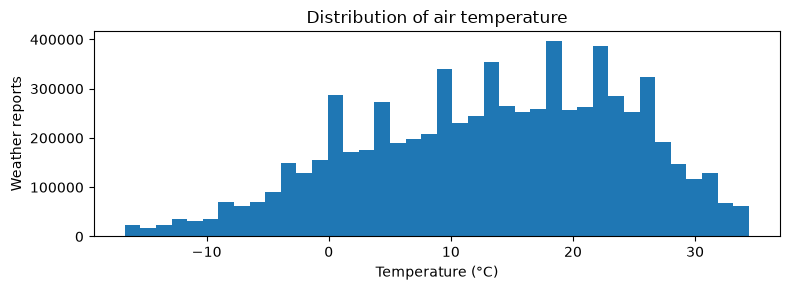

In [15]:
values = weather['HourlyDryBulbTemperature'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of air temperature', xlabel='Temperature (°C)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of wind speed
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

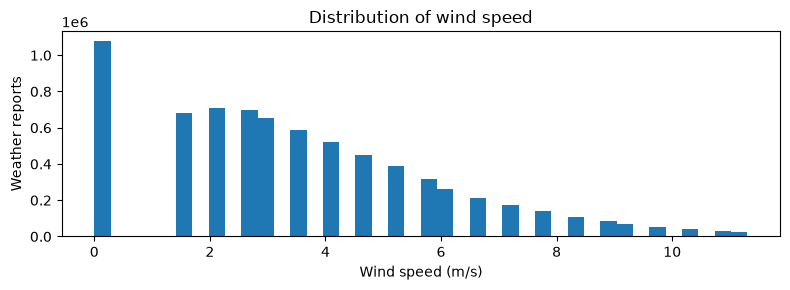

In [16]:
values = weather['HourlyWindSpeed'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of wind speed', xlabel='Wind speed (m/s)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of visibility
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

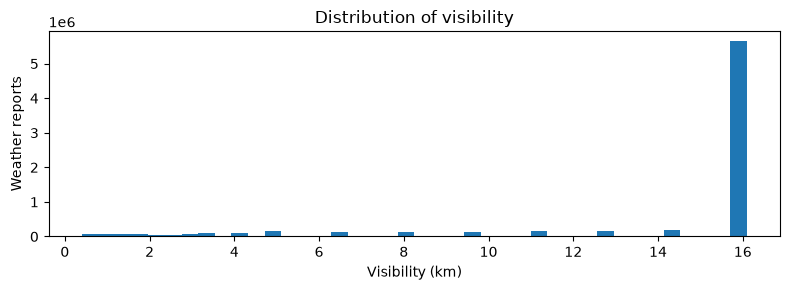

In [17]:
values = weather['HourlyVisibility'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of visibility', xlabel='Visibility (km)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of hourly precipitation
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

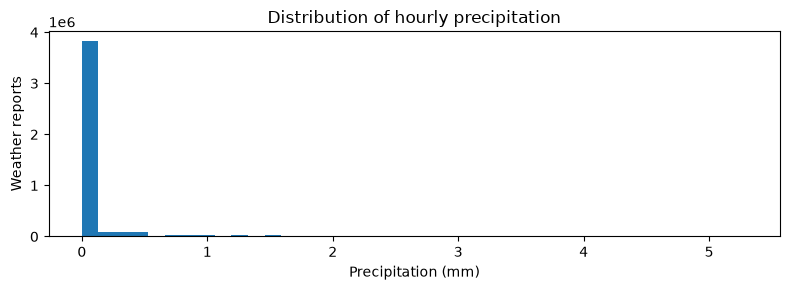

In [18]:
values = weather['HourlyPrecipitation'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of hourly precipitation', xlabel='Precipitation (mm)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of wind gust speed
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

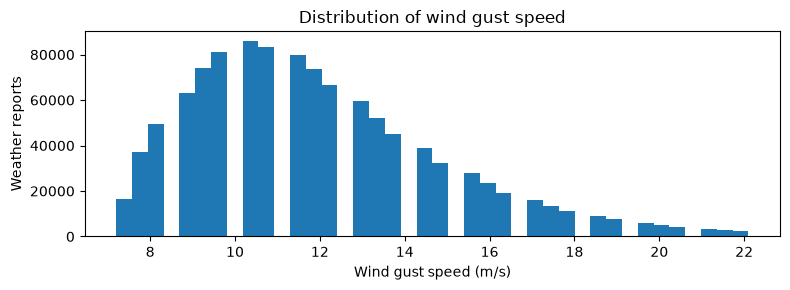

In [19]:
values = weather['HourlyWindGustSpeed'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of wind gust speed', xlabel='Wind gust speed (m/s)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of wind direction
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

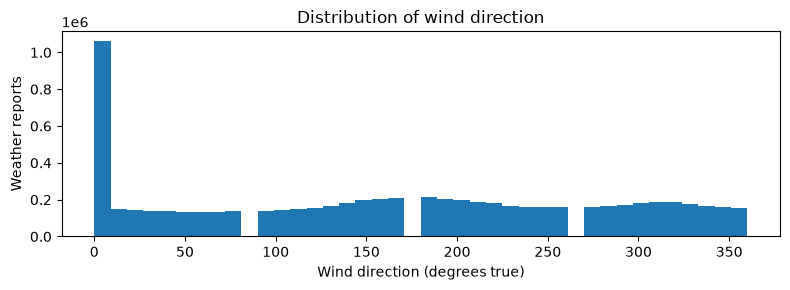

In [20]:
values = weather['HourlyWindDirection'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of wind direction', xlabel='Wind direction (degrees true)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of relative humidity
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

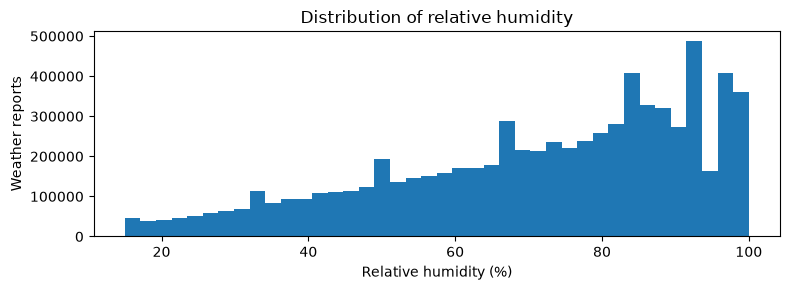

In [21]:
values = weather['HourlyRelativeHumidity'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of relative humidity', xlabel='Relative humidity (%)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of dew point temperature
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

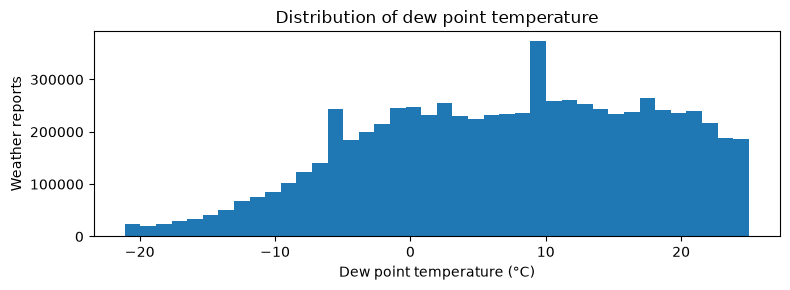

In [22]:
values = weather['HourlyDewPointTemperature'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of dew point temperature', xlabel='Dew point temperature (°C)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Distribution of sea-level pressure
Each histogram shows the middle 98% of numeric values for readability; the summary table keeps the full range.

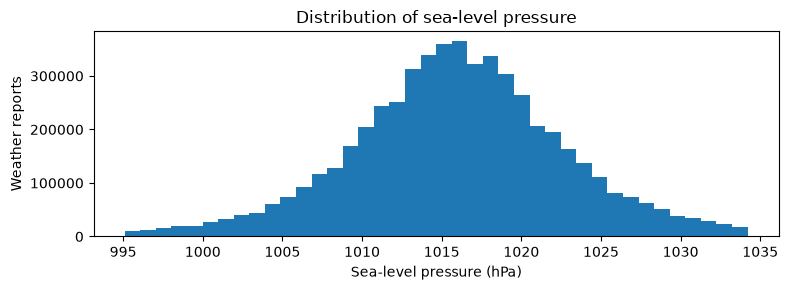

In [23]:
values = weather['HourlySeaLevelPressure'].dropna()
low, high = values.quantile([0.01, 0.99])
# Keep the data unchanged and zoom in for a readable plot.
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of sea-level pressure', xlabel='Sea-level pressure (hPa)', ylabel='Weather reports')
plt.tight_layout()
plt.show()

## Most common weather condition codes
This table shows the ten most frequent original weather condition codes, with blank values shown explicitly and code combinations left unchanged.

In [24]:
pd.Series(code_counts['HourlyPresentWeatherType'], name='reports').sort_values(ascending=False).head(10).to_frame()

,reports
(blank),5762881
BR:1 |BR |,296937
-RA:02 |RA |RA,214743
-RA:02 BR:1 |RA BR |RA,126192
-SN:03 BR:1 |SN BR |SN,115867
-SN:03 |SN |SN,107933
|BR |,82371
FG:2 |FG |,60827
|RA |,46308
RA:02 BR:1 |RA BR |RA,45471


## Most common cloud condition codes
This table shows the ten most frequent original cloud condition codes, with blank values shown explicitly and code combinations left unchanged.

In [25]:
pd.Series(code_counts['HourlySkyConditions'], name='reports').sort_values(ascending=False).head(10).to_frame()

,reports
CLR:00,2009267
(blank),516260
FEW:02 76.2,96179
OVC:08 0.61,63970
OVC:08 0.91,56532
OVC:08 1.22,56078
OVC:08 1.52,50105
VV:09 0.61,43558
BKN:07 76.2,41329
OVC:08 1.83,39542


## Data source
Column definitions and report formats are documented in [NOAA's LCDv2 guide](https://www.ncei.noaa.gov/oa/local-climatological-data/v2/doc/lcdv2_DOCUMENTATION.pdf).